In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
pd.set_option("display.max_columns", None)

In [4]:
df = pd.read_csv("../data/cleaned_diabetes_risk.csv")

In [5]:
print("Dataset shape:", df.shape)

Dataset shape: (15000, 19)


In [6]:
df.head()

,patient_id,age,gender,city,bmi,family_history_diabetes,physical_activity_level,diet_type,smoking_status,alcohol_consumption,hours_sleep_per_night,stress_level,fasting_blood_sugar,hba1c_level,blood_pressure_systolic,blood_pressure_diastolic,waist_circumference_cm,income_bracket,diabetes_risk
0,1,47,Female,Mumbai,26.5,Yes,Sedentary,Vegetarian,Never,Never,9.0,8,178,7.3,146,90,107.1,High,Low
1,2,53,Female,Mumbai,20.5,Yes,Moderate,Vegetarian,Never,Never,7.0,6,152,6.9,156,100,93.8,Low,Low
2,3,47,Male,Thane,31.3,No,Moderate,Non-Vegetarian,Current,Regular,7.0,7,168,6.6,150,102,113.5,Low,High
3,4,41,Male,Bengaluru,22.8,No,Sedentary,Non-Vegetarian,Never,Never,9.0,5,155,6.7,126,92,109.6,Middle,Low
4,5,57,Female,Bengaluru,16.7,No,Sedentary,Non-Vegetarian,Current,Occasional,6.5,10,188,6.7,130,90,80.8,High,Low


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   patient_id                15000 non-null  int64  
 1   age                       15000 non-null  int64  
 2   gender                    15000 non-null  object 
 3   city                      15000 non-null  object 
 4   bmi                       15000 non-null  float64
 5   family_history_diabetes   15000 non-null  object 
 6   physical_activity_level   15000 non-null  object 
 7   diet_type                 15000 non-null  object 
 8   smoking_status            15000 non-null  object 
 9   alcohol_consumption       15000 non-null  object 
 10  hours_sleep_per_night     15000 non-null  float64
 11  stress_level              15000 non-null  int64  
 12  fasting_blood_sugar       15000 non-null  int64  
 13  hba1c_level               15000 non-null  float64
 14  blood_

In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
patient_id,15000.0,7500.500000,4330.271354,1.0,3750.75,7500.5,11250.25,15000.0
age,15000.0,44.333667,10.383753,18.0,38.00,45.0,52.00,80.0
bmi,15000.0,23.062260,4.046391,15.0,20.10,22.7,25.60,40.8
hours_sleep_per_night,15000.0,7.309860,1.109372,3.0,6.70,7.0,8.00,12.0
stress_level,15000.0,5.941200,2.148406,1.0,4.00,6.0,7.00,10.0
fasting_blood_sugar,15000.0,168.789933,38.365822,72.0,145.00,165.0,189.00,400.0
hba1c_level,15000.0,6.878387,0.843276,4.8,6.30,6.8,7.30,13.4
blood_pressure_systolic,15000.0,139.496200,12.660785,80.0,130.00,140.0,150.00,200.0
blood_pressure_diastolic,15000.0,86.256933,8.386529,50.0,80.00,88.0,90.00,120.0
waist_circumference_cm,15000.0,100.207933,10.760331,73.2,92.50,99.3,106.90,148.2


In [9]:
df.describe(include="object").T

,count,unique,top,freq
gender,15000,3,Male,7664
city,15000,18,Mumbai,2243
family_history_diabetes,15000,2,No,9756
physical_activity_level,15000,3,Active,5100
diet_type,15000,4,Non-Vegetarian,8195
smoking_status,15000,4,Never,10119
alcohol_consumption,15000,4,Never,5616
income_bracket,15000,4,Middle,7305
diabetes_risk,15000,3,Low,9000


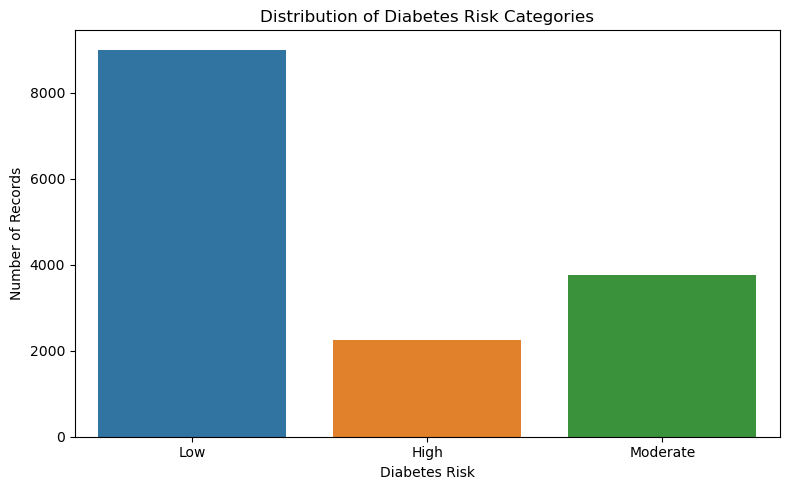

In [10]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="diabetes_risk",
    hue="diabetes_risk",
    legend=False
)

plt.title("Distribution of Diabetes Risk Categories")
plt.xlabel("Diabetes Risk")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

In [11]:
risk_counts = df["diabetes_risk"].value_counts()

risk_percentages = df["diabetes_risk"].value_counts(normalize=True) * 100

risk_summary = pd.DataFrame({
    "Number of Records": risk_counts,
    "Percentage (%)": risk_percentages.round(2)
})

risk_summary

,Number of Records,Percentage (%)
diabetes_risk,,
Low,9000,60.0
Moderate,3750,25.0
High,2250,15.0


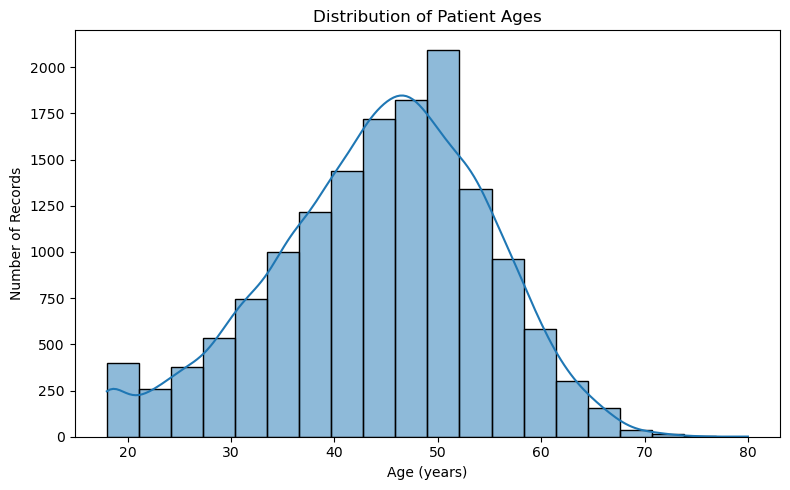

In [12]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="age",
    bins=20,
    kde=True
)

plt.title("Distribution of Patient Ages")
plt.xlabel("Age (years)")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

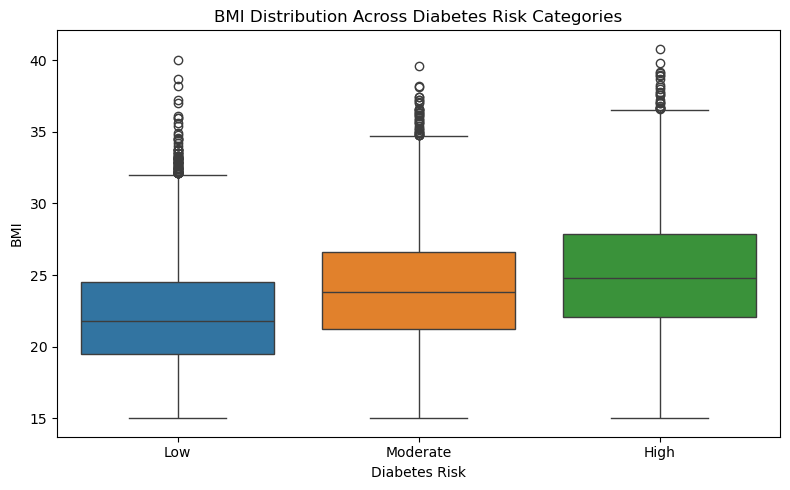

In [13]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="diabetes_risk",
    y="bmi",
    order=["Low", "Moderate", "High"],
    hue="diabetes_risk",
    hue_order=["Low", "Moderate", "High"],
    legend=False
)

plt.title("BMI Distribution Across Diabetes Risk Categories")
plt.xlabel("Diabetes Risk")
plt.ylabel("BMI")
plt.tight_layout()
plt.show()

diabetes_risk
Low         6.429656
Moderate    7.200693
High        8.136133
Name: hba1c_level, dtype: float64


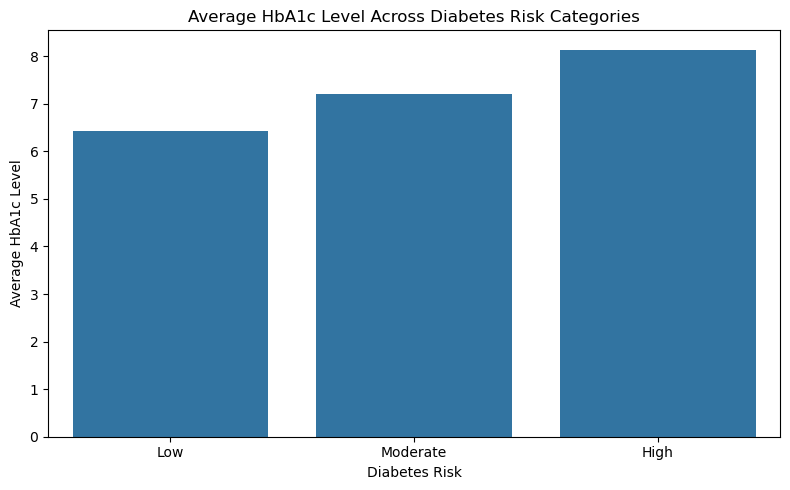

In [14]:

hba1c_summary = (
    df.groupby("diabetes_risk")["hba1c_level"]
    .mean()
    .reindex(["Low", "Moderate", "High"])
)

print(hba1c_summary)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=hba1c_summary.index,
    y=hba1c_summary.values
)

plt.title("Average HbA1c Level Across Diabetes Risk Categories")
plt.xlabel("Diabetes Risk")
plt.ylabel("Average HbA1c Level")
plt.tight_layout()
plt.show()

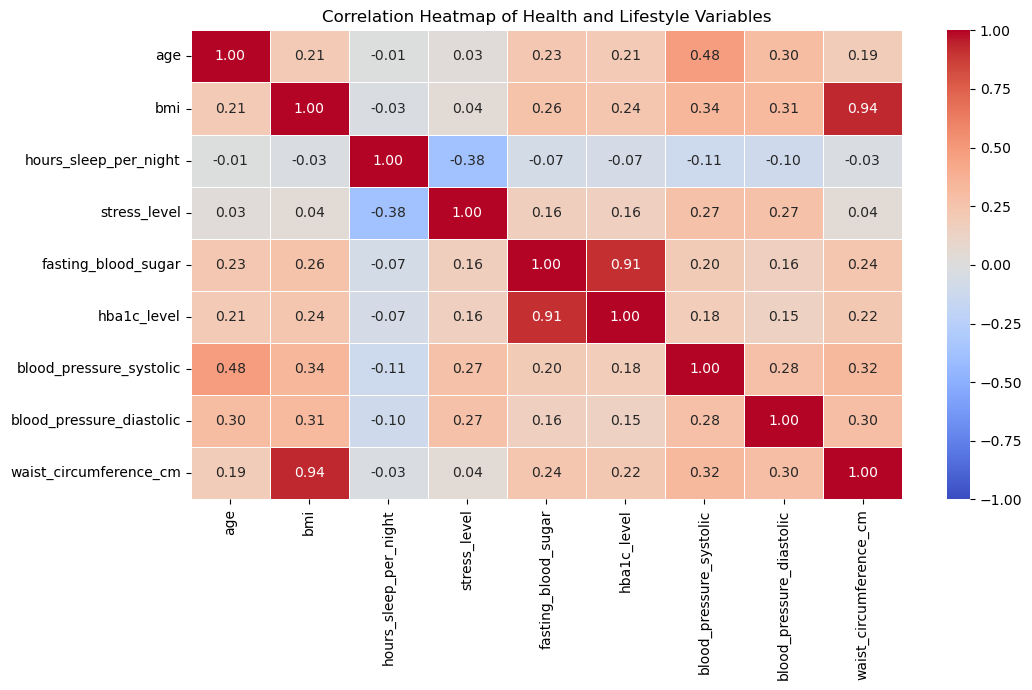

In [15]:
numerical_df = df.select_dtypes(include="number").drop(
    columns=["patient_id"],
    errors="ignore"
)

correlation_matrix = numerical_df.corr()

plt.figure(figsize=(11, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Correlation Heatmap of Health and Lifestyle Variables")
plt.tight_layout()
plt.show()

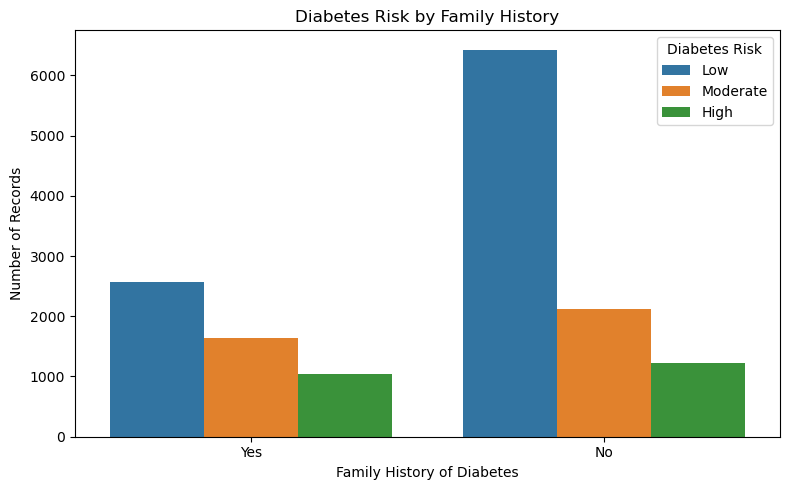

In [16]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="family_history_diabetes",
    hue="diabetes_risk",
    hue_order=["Low", "Moderate", "High"]
)

plt.title("Diabetes Risk by Family History")
plt.xlabel("Family History of Diabetes")
plt.ylabel("Number of Records")
plt.legend(title="Diabetes Risk")
plt.tight_layout()
plt.show()

diabetes_risk              Low  Moderate   High
family_history_diabetes                        
No                       65.86     21.68  12.46
Yes                      49.10     31.18  19.72


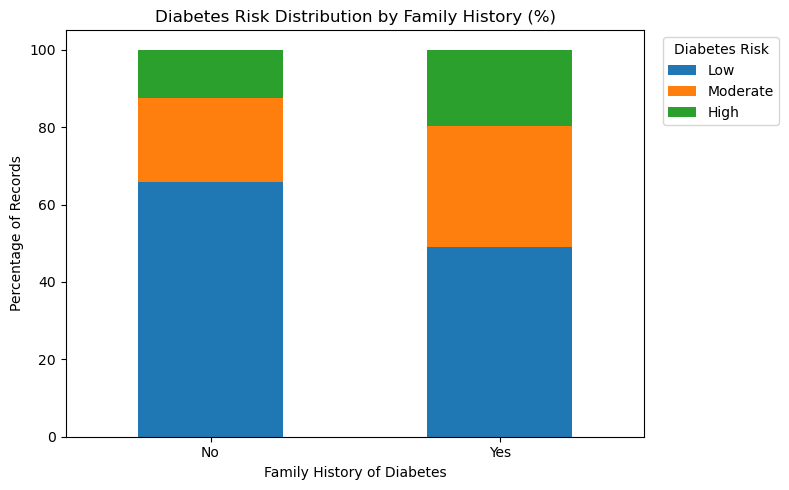

In [17]:
risk_percentages = pd.crosstab(
    df["family_history_diabetes"],
    df["diabetes_risk"],
    normalize="index"
) * 100

risk_percentages = risk_percentages.reindex(
    columns=["Low", "Moderate", "High"]
)

print(risk_percentages.round(2))

risk_percentages.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Diabetes Risk Distribution by Family History (%)")
plt.xlabel("Family History of Diabetes")
plt.ylabel("Percentage of Records")
plt.legend(title="Diabetes Risk", bbox_to_anchor=(1.02, 1))
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

diabetes_risk              Low  Moderate   High
physical_activity_level                        
Active                   70.12     20.10   9.78
Moderate                 59.09     26.55  14.36
Sedentary                50.48     28.51  21.01


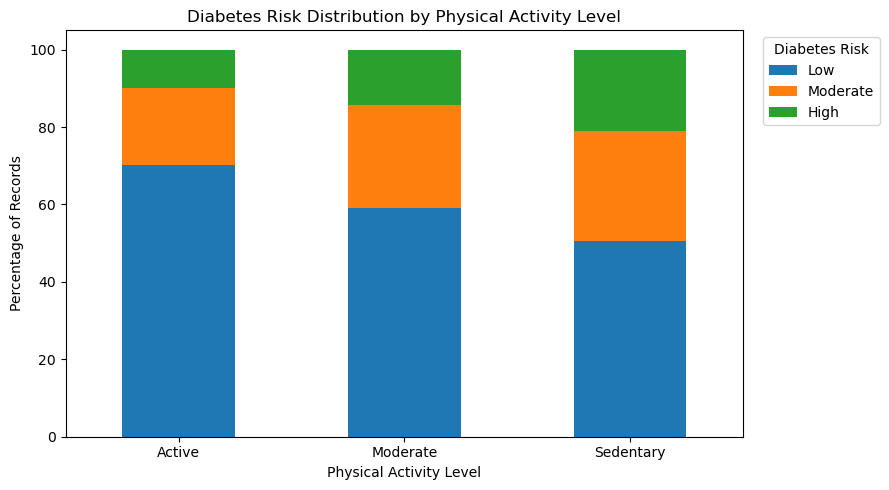

In [18]:
activity_risk = pd.crosstab(
    df["physical_activity_level"],
    df["diabetes_risk"],
    normalize="index"
) * 100

activity_risk = activity_risk.reindex(
    columns=["Low", "Moderate", "High"]
)

print(activity_risk.round(2))

activity_risk.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

plt.title("Diabetes Risk Distribution by Physical Activity Level")
plt.xlabel("Physical Activity Level")
plt.ylabel("Percentage of Records")
plt.legend(title="Diabetes Risk", bbox_to_anchor=(1.02, 1))
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

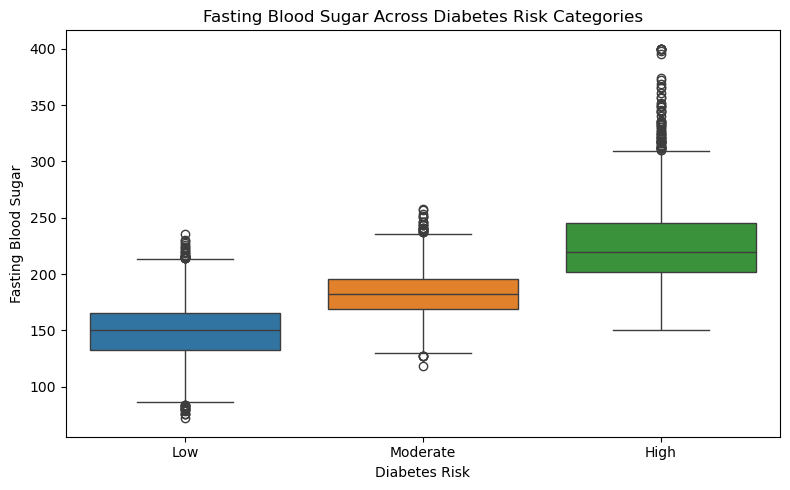

In [19]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="diabetes_risk",
    y="fasting_blood_sugar",
    order=["Low", "Moderate", "High"],
    hue="diabetes_risk",
    hue_order=["Low", "Moderate", "High"],
    legend=False
)

plt.title("Fasting Blood Sugar Across Diabetes Risk Categories")
plt.xlabel("Diabetes Risk")
plt.ylabel("Fasting Blood Sugar")
plt.tight_layout()
plt.show()

In [20]:
df.groupby("diabetes_risk")["fasting_blood_sugar"].agg(
    ["count", "mean", "median", "std", "min", "max"]
).reindex(["Low", "Moderate", "High"]).round(2)

,count,mean,median,std,min,max
diabetes_risk,,,,,,
Low,9000,148.30,150.0,24.87,72,236
Moderate,3750,183.32,182.0,19.73,118,258
High,2250,226.54,220.0,36.40,150,400


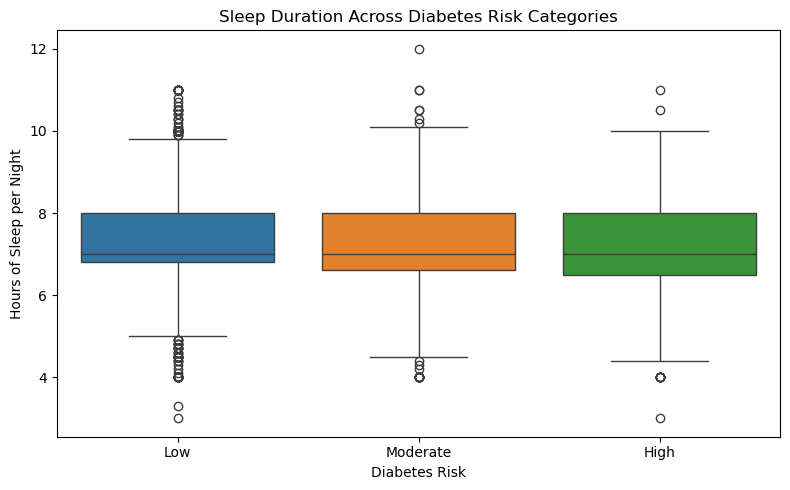

In [21]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="diabetes_risk",
    y="hours_sleep_per_night",
    order=["Low", "Moderate", "High"],
    hue="diabetes_risk",
    hue_order=["Low", "Moderate", "High"],
    legend=False
)

plt.title("Sleep Duration Across Diabetes Risk Categories")
plt.xlabel("Diabetes Risk")
plt.ylabel("Hours of Sleep per Night")
plt.tight_layout()
plt.show()

In [22]:
sleep_summary = (
    df.groupby("diabetes_risk")["hours_sleep_per_night"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .reindex(["Low", "Moderate", "High"])
)

sleep_summary.round(2)

,count,mean,median,std,min,max
diabetes_risk,,,,,,
Low,9000,7.35,7.0,1.12,3.0,11.0
Moderate,3750,7.27,7.0,1.10,4.0,12.0
High,2250,7.23,7.0,1.10,3.0,11.0
